# Lab 7: K-Means Clustering

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Aim
Perform K-Means clustering on a suitable dataset and examine the groups formed.

## Dataset: Kaggle Credit Card Customers


## 1. Import libraries


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## 2. Load and inspect the dataset



In [5]:
csv_candidates = [
    Path("/kaggle/input/ccdata/CC GENERAL.csv"),
    Path("/kaggle/input/credit-card-customers/CC GENERAL.csv"),
    Path("CC GENERAL.csv"),
    Path("CC_GENERAL.csv"),
    Path("data/CC GENERAL.csv"),
    Path("data/CC_GENERAL.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

# Search Kaggle input folders if the dataset has a different folder name
if csv_path is None and Path("/kaggle/input").exists():
    matches = list(Path("/kaggle/input").rglob("CC GENERAL.csv"))
    if matches:
        csv_path = matches[0]

if csv_path is None:
    raise FileNotFoundError(
        "Could not find CC GENERAL.csv. Download it from the Kaggle dataset page and "
        "place it beside this notebook (or in ./data/CC GENERAL.csv). On Kaggle, attach "
        "the dataset so it is available under /kaggle/input/."
    )

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
df.head()

Loaded file: CC GENERAL.csv
Dataset shape: (8950, 18)

First five rows:


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [6]:
# Review column types and missing values
print("Column data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Column data types:
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

Missing values per column:
MINIMUM_PAYMENTS          313
CREDIT_LIMIT                1
BALANCE                     0
CUST_ID                     0
BALANCE_FREQUENCY          

## 3. Select features and handle missing values


In [7]:
features = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT",
    "PAYMENTS", "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT", "TENURE"
]

X = df[features].copy()
print("Selected feature count:", len(features))
print("Missing values before imputation:")
print(X.isnull().sum())

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X), columns=features, index=X.index
)
print("\nTotal missing values after imputation:", X_imputed.isnull().sum().sum())

Selected feature count: 10
Missing values before imputation:
BALANCE                     0
PURCHASES                   0
ONEOFF_PURCHASES            0
INSTALLMENTS_PURCHASES      0
CASH_ADVANCE                0
CREDIT_LIMIT                1
PAYMENTS                    0
MINIMUM_PAYMENTS          313
PRC_FULL_PAYMENT            0
TENURE                      0
dtype: int64

Total missing values after imputation: 0


## 4. Standardize the features


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print("Shape of standardized feature matrix:", X_scaled.shape)

Shape of standardized feature matrix: (8950, 10)


## 5. Choose a suitable number of clusters


In [9]:
k_values = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

score_table = pd.DataFrame({
    "K (number of clusters)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette score": silhouette_values
})
score_table.round(3)

,K (number of clusters),Inertia,Silhouette score
0,2,73678.585,0.475
1,3,63908.812,0.392
2,4,56012.302,0.330
3,5,49258.973,0.364
4,6,43995.973,0.362
5,7,39458.452,0.369
6,8,36230.474,0.364


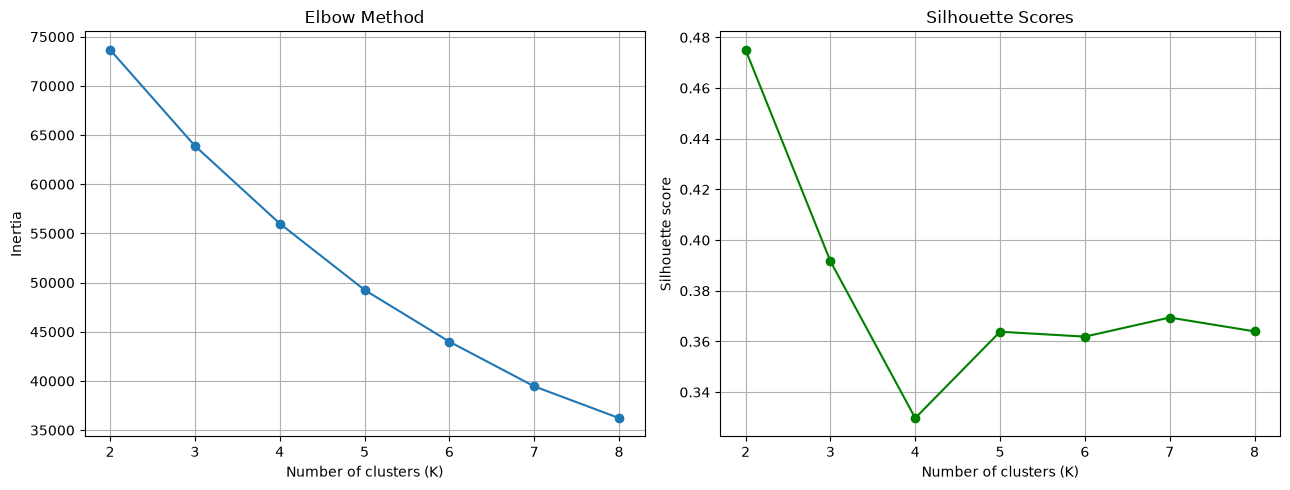

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(list(k_values), silhouette_values, marker="o", color="green")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 6. Fit the final K-Means model



In [11]:
best_k = list(k_values)[int(pd.Series(silhouette_values).idxmax())]
print("Selected number of clusters (highest tested silhouette):", best_k)

final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = final_model.fit_predict(X_scaled)

clustered_df = X_imputed.copy()
clustered_df["Cluster"] = cluster_labels
clustered_df.head()

Selected number of clusters (highest tested silhouette): 2


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084,139.509787,0.000000,12.0,1
1,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597,1072.340217,0.222222,12.0,0
2,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742,627.284787,0.000000,12.0,1
3,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000,312.343947,0.000000,12.0,1
4,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763,244.791237,0.000000,12.0,1


## 7. Examine cluster sizes and profiles



In [12]:
print("Number of customers in each cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("Customer count"))

print("Average feature values by cluster (original units):")
cluster_profiles = clustered_df.groupby("Cluster")[features].mean()
display(cluster_profiles.round(2))

Number of customers in each cluster:


,Customer count
Cluster,
0,1276
1,7674


Average feature values by cluster (original units):


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,
0,4857.95,3197.43,2091.78,1106.19,3329.47,9779.12,5548.69,2523.94,0.12,11.77
1,1016.85,638.36,343.13,295.49,588.02,3615.54,1098.71,565.72,0.16,11.48


## 8. Visualize clusters using PCA



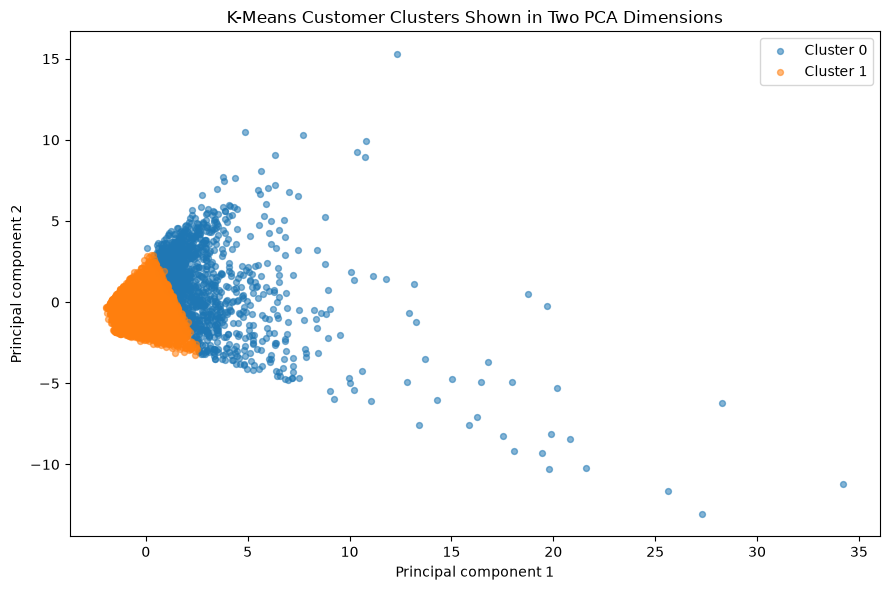

Variance represented by the two plotted components: 0.526


In [13]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "Principal component 1": X_2d[:, 0],
    "Principal component 2": X_2d[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(9, 6))
for cluster in sorted(plot_df["Cluster"].unique(), key=int):
    cluster_points = plot_df[plot_df["Cluster"] == cluster]
    plt.scatter(
        cluster_points["Principal component 1"],
        cluster_points["Principal component 2"],
        label=f"Cluster {cluster}", alpha=0.55, s=18
    )
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("K-Means Customer Clusters Shown in Two PCA Dimensions")
plt.legend()
plt.tight_layout()
plt.show()

print("Variance represented by the two plotted components:",
      round(pca.explained_variance_ratio_.sum(), 3))